# CONCH · GPT R2 · Magnification and scale

Run all cells in order. Acquisition, image processing, axis construction, inference, controls and the decision are written in this notebook. Python3.11 is used with PyTorch2.5.0, torchvision0.20.0, NumPy1.26.4, pandas2.2.2, scikit-learn1.5.2, Pillow10.4.0, pyarrow16.1.0, statsmodels0.14.2 and the pinned official CONCH library. Install CONCH from `git+https://github.com/mahmoodlab/CONCH.git@141cc09c7d4ff33d8eda562bd75169b457f71a62`. Your Hugging Face account must have access to the CONCH weights.

## 1. Data source / acquisition

CRC-VAL-HE-7K and the NCT reference come from the pinned public Hugging Face dataset revision. The reference selects 4,860 tiles: 540 per tissue class, using the specified parquet row groups and evenly spaced records. Stanford comes from its pinned public normalized validation archive. The code downloads the image bytes; existing downloads are reused only after identity checks.

**Environment setup before starting the kernel (Linux, Python 3.11):**

Create this shared GPT/Kimi environment before opening the notebook. Keep it separate from the primary CONCH environment, which uses different numerical-library versions.

```bash
python3.11 -m venv .venv-conch-shared
.venv-conch-shared/bin/python -m pip install torch==2.5.0 torchvision==0.20.0 --index-url https://download.pytorch.org/whl/cu124
.venv-conch-shared/bin/python -m pip install numpy==1.26.4 scipy==1.13.1 pandas==2.2.2 scikit-learn==1.5.2 Pillow==10.4.0 pyarrow==16.1.0 scikit-image==0.24.0 statsmodels==0.14.2 opencv-python-headless==4.10.0.84
.venv-conch-shared/bin/python -m pip install matplotlib==3.9.4 timm==0.9.16 transformers==4.40.1 tokenizers==0.19.1 huggingface-hub==0.23.5 ftfy==6.3.1 h5py==3.11.0 open-clip-torch==2.24.0 requests==2.34.2 regex==2026.11.9 safetensors==0.8.0 nbformat==5.10.4 nbclient==0.10.4 nbconvert==7.16.6 ipykernel==6.29.5
.venv-conch-shared/bin/python -m pip install --no-deps "git+https://github.com/mahmoodlab/CONCH.git@141cc09c7d4ff33d8eda562bd75169b457f71a62"
.venv-conch-shared/bin/python -m ipykernel install --user --name conch-gpt-kimi-inline --display-name "CONCH GPT/Kimi"
```

Select **CONCH GPT/Kimi** before Run All. The CUDA 12.4 wheels require a compatible NVIDIA driver; the code also selects CPU if CUDA is unavailable. Authenticate with Hugging Face using an account that can access `MahmoodLab/conch` before the checkpoint-download cell. The `huggingface-cli login` command is provided by the pinned Hub package.

The default input directory is `inputs/` below the notebook working directory. Set `CONCH_INPUTS` before starting the kernel to reuse a shared raw-input directory. The notebook verifies its declared downloaded inputs and runs the calculations shown below, including the stated scoring or eligibility diagnostic. All analysis-specific functions are inline; the installed CONCH package is the pinned public model implementation.

The CONCH model-input transform is explicitly set to 224×224 in the scoring cell. Reference-network weights and transforms are specified in that same cell.


In [1]:
AXIS=6
AXIS_NAME='Magnification and scale'
CRC_SHARDS=['data/CRC_VAL_HE_7K-00000-of-00003-cce1097526b69125.parquet',
 'data/CRC_VAL_HE_7K-00001-of-00003-fbb5de8b1164f4ea.parquet',
 'data/CRC_VAL_HE_7K-00002-of-00003-2009e87e0c48fccf.parquet']
REFERENCE_SHARDS=[{'label': 'ADI',
  'shard': 'NCT_CRC_HE_100K-00007-of-00031-7240d4f64e3ab056.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00007-of-00031-7240d4f64e3ab056.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'ADI',
  'shard': 'NCT_CRC_HE_100K-00008-of-00031-164c2dc788d56bcd.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00008-of-00031-164c2dc788d56bcd.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'ADI',
  'shard': 'NCT_CRC_HE_100K-00009-of-00031-a88ca52bf61c4a65.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00009-of-00031-a88ca52bf61c4a65.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'BACK',
  'shard': 'NCT_CRC_HE_100K-00021-of-00031-e828a2a9aff921c7.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00021-of-00031-e828a2a9aff921c7.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'BACK',
  'shard': 'NCT_CRC_HE_100K-00022-of-00031-179504506f62afff.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00022-of-00031-179504506f62afff.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'BACK',
  'shard': 'NCT_CRC_HE_100K-00023-of-00031-0c174269fdc04fcd.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00023-of-00031-0c174269fdc04fcd.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'DEB',
  'shard': 'NCT_CRC_HE_100K-00000-of-00031-9780c9afe3d80c58.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00000-of-00031-9780c9afe3d80c58.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'DEB',
  'shard': 'NCT_CRC_HE_100K-00001-of-00031-89eb0ee8f756b1d1.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00001-of-00031-89eb0ee8f756b1d1.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'DEB',
  'shard': 'NCT_CRC_HE_100K-00002-of-00031-0ee839cd355aeab1.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00002-of-00031-0ee839cd355aeab1.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'LYM',
  'shard': 'NCT_CRC_HE_100K-00010-of-00031-10d1d039bbb1e518.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00010-of-00031-10d1d039bbb1e518.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'LYM',
  'shard': 'NCT_CRC_HE_100K-00011-of-00031-9586fd31243bcf81.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00011-of-00031-9586fd31243bcf81.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'LYM',
  'shard': 'NCT_CRC_HE_100K-00012-of-00031-68088e297e94d57f.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00012-of-00031-68088e297e94d57f.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'MUC',
  'shard': 'NCT_CRC_HE_100K-00024-of-00031-6724461c96053f0e.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00024-of-00031-6724461c96053f0e.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 270},
 {'label': 'MUC',
  'shard': 'NCT_CRC_HE_100K-00025-of-00031-06d3e29beab848cc.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00025-of-00031-06d3e29beab848cc.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 270},
 {'label': 'MUS',
  'shard': 'NCT_CRC_HE_100K-00027-of-00031-76ba1a4a6d60e4bf.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00027-of-00031-76ba1a4a6d60e4bf.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'MUS',
  'shard': 'NCT_CRC_HE_100K-00028-of-00031-6161e17b52896e1b.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00028-of-00031-6161e17b52896e1b.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'MUS',
  'shard': 'NCT_CRC_HE_100K-00029-of-00031-01d8069141f86ca7.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00029-of-00031-01d8069141f86ca7.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'NORM',
  'shard': 'NCT_CRC_HE_100K-00014-of-00031-a59185824004206f.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00014-of-00031-a59185824004206f.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 270},
 {'label': 'NORM',
  'shard': 'NCT_CRC_HE_100K-00015-of-00031-72d58c4f33fb37a0.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00015-of-00031-72d58c4f33fb37a0.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 270},
 {'label': 'STR',
  'shard': 'NCT_CRC_HE_100K-00004-of-00031-04197e7c2252e508.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00004-of-00031-04197e7c2252e508.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 270},
 {'label': 'STR',
  'shard': 'NCT_CRC_HE_100K-00005-of-00031-6929e3c0e6f21267.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00005-of-00031-6929e3c0e6f21267.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 270},
 {'label': 'TUM',
  'shard': 'NCT_CRC_HE_100K-00017-of-00031-240fc2989151d739.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00017-of-00031-240fc2989151d739.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'TUM',
  'shard': 'NCT_CRC_HE_100K-00018-of-00031-84ed50962a18a85e.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00018-of-00031-84ed50962a18a85e.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180},
 {'label': 'TUM',
  'shard': 'NCT_CRC_HE_100K-00019-of-00031-e4a4c7209859272a.parquet',
  'url': 'https://huggingface.co/datasets/1aurent/NCT-CRC-HE/resolve/97765ecb14bf11ce7bb8779a1097d187844a67cb/data/NCT_CRC_HE_100K-00019-of-00031-e4a4c7209859272a.parquet?download=true',
  'row_groups': [2, 16, 30],
  'selected': 180}]
AXIS_FEATURES=['rgb_r_mean',
 'rgb_g_mean',
 'rgb_b_mean',
 'rgb_r_std',
 'rgb_g_std',
 'rgb_b_std',
 'rgb_r_q10',
 'rgb_g_q10',
 'rgb_b_q10',
 'rgb_r_q90',
 'rgb_g_q90',
 'rgb_b_q90',
 'od_r_mean',
 'od_g_mean',
 'od_b_mean',
 'od_r_std',
 'od_g_std',
 'od_b_std',
 'saturation_mean',
 'saturation_std',
 'saturation_q90',
 'gray_std',
 'gray_entropy',
 'contrast_horizontal',
 'contrast_vertical',
 'edge_mean',
 'edge_std',
 'gray_mean',
 'gray_q05',
 'gray_q50',
 'gray_q95',
 'tissue_fraction',
 'white_fraction',
 'dark_fraction']

from pathlib import Path
import concurrent.futures,hashlib,io,json,os,shutil,time,zipfile
import requests
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from PIL import Image as PILImage
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,Image
from huggingface_hub import hf_hub_download,hf_hub_url,get_hf_file_metadata
from sklearn.neighbors import NearestNeighbors,NearestCentroid
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

INPUT=Path(os.environ.get('CONCH_INPUTS',Path.cwd()/'inputs'));INPUT.mkdir(parents=True,exist_ok=True)
OUT=Path.cwd()/f'conch-gpt-r2-test-{AXIS:02}-outputs';OUT.mkdir(exist_ok=True)
CLASSES=['ADI','BACK','DEB','LYM','MUC','MUS','NORM','STR','TUM']
CLASS_MAP={'ADI':'ADI','BACK':'BACK','DEB':'DEB','LYM':'LYM','MUC':'MUC','MUS':'MUS','NORM':'NORM','STR':'STR','TUM':'TUM','NCS':'DEB','NOR':'NORM','FCT':'STR','BLD':None}
REVISION='97765ecb14bf11ce7bb8779a1097d187844a67cb'
SOURCE_REVISION='141cc09c7d4ff33d8eda562bd75169b457f71a62'
CHECKPOINT_REVISION='f9ca9f877171a28ade80228fb195ac5d79003357'
SEED=20260715

def sha256(path):
    digest=hashlib.sha256()
    with open(path,'rb') as source:
        for block in iter(lambda:source.read(8<<20),b''):digest.update(block)
    return digest.hexdigest()

def show_figure(figure):
    output=io.BytesIO();figure.savefig(output,format='png',dpi=130,bbox_inches='tight')
    display(Image(data=output.getvalue()));plt.close(figure)

def download(url,destination,expected_sha256=None,expected_bytes=None):
    destination=Path(destination);destination.parent.mkdir(parents=True,exist_ok=True)
    if destination.is_file() and (expected_bytes is None or destination.stat().st_size==expected_bytes) and (expected_sha256 is None or sha256(destination)==expected_sha256):return destination
    temporary=destination.with_name(destination.name+f'.{os.getpid()}.part')
    with requests.get(url,stream=True,timeout=120) as response:
        response.raise_for_status()
        with open(temporary,'wb') as target:
            for block in response.iter_content(8<<20):target.write(block)
    if expected_bytes is not None:assert temporary.stat().st_size==expected_bytes
    if expected_sha256 is not None:assert sha256(temporary)==expected_sha256
    temporary.replace(destination);return destination

def pinned_parquet(filename):
    url=hf_hub_url('1aurent/NCT-CRC-HE',filename,repo_type='dataset',revision=REVISION)
    metadata=get_hf_file_metadata(url)
    digest=metadata.etag.strip('"')
    assert len(digest)==64,'Expected a large-file SHA-256 identity'
    return download(url,INPUT/'hf_parquet'/filename,digest,metadata.size)

stanford_record=dict(url='https://huggingface.co/datasets/Path2AI/STARC-9/resolve/2c4b716dc5370c9628162ceb9190f0b92eaafd3c/Validation_data/STANFORD-CRC-HE-VAL-SMALL-NORMALIZED.zip',sha256='088281de09bfe4d57b4a8e356a99cdb9b002a08a0ff7c44910aee0b4de81d3f3',bytes=2149005637)
stanford_archive=download(stanford_record['url'],INPUT/'STANFORD-CRC-HE-VAL-SMALL-NORMALIZED.zip',stanford_record['sha256'],stanford_record['bytes'])
with concurrent.futures.ThreadPoolExecutor(max_workers=3) as pool:
    crc_paths=list(pool.map(pinned_parquet,CRC_SHARDS))
display(pd.DataFrame([dict(source='CRC-VAL',url=hf_hub_url('1aurent/NCT-CRC-HE',name,repo_type='dataset',revision=REVISION),path=str(path),sha256=sha256(path)) for name,path in zip(CRC_SHARDS,crc_paths)]+[dict(source='Stanford',url=stanford_record['url'],path=str(stanford_archive),sha256=stanford_record['sha256'])]))


/ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,source,url,path,sha256
0,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,/ewsc/yektefai/spectra_runs/conch_nonprimary_r...,fc4aa78c380802f27e59a70b2f2877dc3d2b82ddc2b800...
1,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,/ewsc/yektefai/spectra_runs/conch_nonprimary_r...,d607ebd6b861e3aec2ae2d457993f42222393abb9bdd99...
2,CRC-VAL,https://huggingface.co/datasets/1aurent/NCT-CR...,/ewsc/yektefai/spectra_runs/conch_nonprimary_r...,d733e143f0c984d24262d7b98d30669a885e7a6e3fcb46...
3,Stanford,https://huggingface.co/datasets/Path2AI/STARC-...,/ewsc/yektefai/spectra_runs/conch_nonprimary_r...,088281de09bfe4d57b4a8e356a99cdb9b002a08a0ff7c4...


In [2]:
class RangeFile(io.RawIOBase):
    def __init__(self, url):
        super().__init__()
        self.url, self.position, self.ranges, self.receipts = url, 0, [], []
        response = requests.get(url, headers={'Range': 'bytes=-8'}, timeout=60)
        response.raise_for_status()
        assert response.status_code == 206
        self.size = int(response.headers['Content-Range'].split('/')[-1])
        self.ranges.append((self.size - 8, response.content))

    def readable(self): return True
    def seekable(self): return True
    def tell(self): return self.position
    def seek(self, offset, whence=0):
        self.position = offset if whence == 0 else self.position + offset if whence == 1 else self.size + offset
        return self.position

    def read(self, size=-1):
        if size < 0: size = self.size - self.position
        size = min(size, self.size - self.position)
        start = self.position
        self.position += size
        if not size: return b''
        for offset, raw in self.ranges:
            if offset <= start and start + size <= offset + len(raw):
                return raw[start-offset:start-offset+size]
        assert size < 20_000_000, f'Unexpected bulk read: {size}'
        response = requests.get(self.url, headers={'Range': f'bytes={start}-{start+size-1}'}, timeout=120)
        response.raise_for_status()
        assert response.status_code == 206 and len(response.content) == size
        raw = response.content
        self.ranges.append((start, raw))
        self.receipts.append({'start': start, 'length': size, 'sha256': hashlib.sha256(raw).hexdigest(),
                              'content_range': response.headers.get('Content-Range')})
        return raw


def save_image(raw,source,source_key,label):
    encoded_hash=hashlib.sha256(raw).hexdigest()
    path=INPUT/'raw_images'/source/(encoded_hash+'.image')
    path.parent.mkdir(parents=True,exist_ok=True)
    if not path.exists() or sha256(path)!=encoded_hash:
        temporary=path.with_name(path.name+f'.{os.getpid()}.part');temporary.write_bytes(raw);temporary.replace(path)
    return dict(cohort=source,source_key=source_key,tile_id=encoded_hash,path=str(path),raw_label=label,encoded_sha256=encoded_hash)

crc_rows=[]
for source_name,path in zip(CRC_SHARDS,crc_paths):
    parquet=pq.ParquetFile(path)
    for group in range(parquet.num_row_groups):
        for index,example in enumerate(parquet.read_row_group(group,columns=['image','label']).to_pylist()):
            image=example['image'];label=CLASSES[int(example['label'])]
            source_key=f'{source_name}:{group}:{index}:{image.get("path","")}'
            crc_rows.append(save_image(image['bytes'],'CRC',source_key,label))
stanford_rows=[]
with zipfile.ZipFile(stanford_archive) as archive:
    for member in sorted(archive.namelist()):
        if not member.lower().endswith(('.png','.tif','.tiff','.jpg','.jpeg')):continue
        label=Path(member).parent.name
        assert label in CLASS_MAP,label
        stanford_rows.append(save_image(archive.read(member),'Stanford',member,label))

def reference_shard(record):
    # The pinned parquet revision and declared row groups fix this bounded panel.
    stream=RangeFile(record['url'])
    parquet=pq.ParquetFile(stream)
    candidates=[]
    for group in record['row_groups']:
        for index,example in enumerate(parquet.read_row_group(group,columns=['image','label']).to_pylist()):
            if CLASSES[int(example['label'])]!=record['label']:continue
            candidates.append((group,index,example))
    assert len(candidates)>=record['selected'],record['shard']
    selected=np.linspace(0,len(candidates)-1,record['selected'],dtype=int)
    rows=[]
    for chosen in selected:
        group,index,example=candidates[chosen]
        key=f'{record["shard"]}:{group}:{index}:{example["image"].get("path","")}'
        rows.append(save_image(example['image']['bytes'],'NCT-reference',key,record['label']))
    return rows,dict(shard=record['shard'],url=record['url'],row_groups=record['row_groups'],selected=record['selected'],range_receipts=stream.receipts)

reference_rows=[];reference_receipts=[]
reference_manifest=INPUT/'gpt2_reference_raw_manifest.json'
if reference_manifest.exists():
    cached=json.loads(reference_manifest.read_text())
    for row in cached['images']:assert sha256(row['path'])==row['encoded_sha256']
    reference_rows=cached['images'];reference_receipts=cached['requests']
else:
    with concurrent.futures.ThreadPoolExecutor(max_workers=4) as pool:
        for rows,receipt in pool.map(reference_shard,REFERENCE_SHARDS):
            reference_rows.extend(rows);reference_receipts.append(receipt)
    temporary=reference_manifest.with_name(reference_manifest.name+f'.{os.getpid()}.part')
    temporary.write_text(json.dumps(dict(images=reference_rows,requests=reference_receipts),indent=2));temporary.replace(reference_manifest)
raw_index=pd.DataFrame(crc_rows+stanford_rows+reference_rows)
raw_index.to_csv(OUT/'raw_image_index.csv.gz',index=False)
display(raw_index.groupby(['cohort','raw_label']).size().unstack(fill_value=0))
assert len(crc_rows)==7180 and len(reference_rows)==4860


raw_label,ADI,BACK,BLD,DEB,FCT,LYM,MUC,MUS,NCS,NOR,NORM,STR,TUM
cohort,,,,,,,,,,,,,
CRC,1338,847,0,339,0,634,1035,592,0,0,741,421,1233
NCT-reference,540,540,0,540,0,540,540,540,0,0,540,540,540
Stanford,2000,0,2000,0,2000,2000,2000,2000,2000,2000,0,0,2000


## 2. Data processing

Deduplicate exact image content and calculate RGB, optical-density, texture, tissue and quality measurements from pixels. Preserve Stanford blood tiles during level construction, then exclude their unmatched class from model evaluation. NCS maps to DEB, NOR to NORM and FCT to STR.

In [3]:
def image_features(row):
    with PILImage.open(row.path) as image:
        rgb=np.asarray(image.convert('RGB'),dtype=np.float32)/255
        hsv=np.asarray(image.convert('HSV'),dtype=np.float32)/255
    gray=rgb@np.array([.299,.587,.114],dtype=np.float32)
    saturation=hsv[...,1];value=hsv[...,2]
    od=-np.log(np.clip(rgb,1/255,1))
    dx=np.diff(gray,axis=1);dy=np.diff(gray,axis=0)
    edge=np.sqrt(dx[:-1,:]**2+dy[:,:-1]**2)
    padded=np.pad(gray,1,mode='reflect')
    lap=padded[:-2,1:-1]+padded[2:,1:-1]+padded[1:-1,:-2]+padded[1:-1,2:]-4*gray
    histogram=np.histogram(gray,bins=64,range=(0,1))[0].astype(float)
    probability=histogram[histogram>0]/histogram.sum()
    power=np.abs(np.fft.fftshift(np.fft.fft2(gray-gray.mean())))**2
    yy,xx=np.indices(gray.shape);radius=np.hypot(yy-gray.shape[0]/2,xx-gray.shape[1]/2)/(max(gray.shape)/2)
    h_bound=np.abs(dx[:,7::8]).mean();v_bound=np.abs(dy[7::8,:]).mean()
    h_inner=np.abs(np.delete(dx,np.arange(7,dx.shape[1],8),axis=1)).mean()
    v_inner=np.abs(np.delete(dy,np.arange(7,dy.shape[0],8),axis=0)).mean()
    result=dict(tile_id=row.tile_id,cohort=row.cohort,gray_std=float(gray.std()),gray_entropy=float(-(probability*np.log2(probability)).sum()),contrast_horizontal=float(np.abs(dx).mean()),contrast_vertical=float(np.abs(dy).mean()),edge_mean=float(edge.mean()),edge_std=float(edge.std()),gray_mean=float(gray.mean()),gray_q05=float(np.quantile(gray,.05)),gray_q50=float(np.quantile(gray,.5)),gray_q95=float(np.quantile(gray,.95)),saturation_mean=float(saturation.mean()),saturation_std=float(saturation.std()),saturation_q90=float(np.quantile(saturation,.9)),tissue_fraction=float(((saturation>.08)&(value<.92)).mean()),white_fraction=float((value>.95).mean()),dark_fraction=float((gray<.1).mean()),laplacian_variance=float(lap.var()),hf_power_ratio=float(power[radius>.5].sum()/(power.sum()+1e-12)),jpeg_blockiness=float((h_bound+v_bound)/(h_inner+v_inner+1e-12)))
    for index,channel in enumerate('rgb'):
        result.update({f'rgb_{channel}_mean':float(rgb[...,index].mean()),f'rgb_{channel}_std':float(rgb[...,index].std()),f'rgb_{channel}_q10':float(np.quantile(rgb[...,index],.1)),f'rgb_{channel}_q90':float(np.quantile(rgb[...,index],.9)),f'od_{channel}_mean':float(od[...,index].mean()),f'od_{channel}_std':float(od[...,index].std())})
    return result

# Deduplicate encoded content within cohorts before calculating features.
index=raw_index.drop_duplicates(['cohort','encoded_sha256']).reset_index(drop=True)
print('Exact duplicate exclusions:',len(raw_index)-len(index))
index['label']=index.raw_label.map(CLASS_MAP)
with concurrent.futures.ThreadPoolExecutor(max_workers=8) as pool:
    features=pd.DataFrame(pool.map(image_features,index.itertuples(index=False)))
data=index.merge(features,on=['cohort','tile_id'],validate='one_to_one')
assert np.isfinite(data[AXIS_FEATURES].to_numpy()).all()
data.to_parquet(OUT/'image_features.parquet',index=False)
display(data.groupby('cohort').size().rename('Unique images'))


Exact duplicate exclusions: 51


cohort
CRC               7180
NCT-reference     4860
Stanford         17949
Name: Unique images, dtype: int64

## 3. Axis definition and level construction

NCT and CRC are documented at a cohort-level 0.5 microns per pixel. This is constant within those cohorts. Inspect the image metadata for an explicit per-tile spatial scale; image dimensions alone do not determine magnification.

In [4]:
metadata_rows=[]
for cohort,frame in data.groupby('cohort'):
    found=0;pixels=[]
    for path in frame.path:
        with PILImage.open(path) as image:
            fields={str(key).lower():str(value) for key,value in image.info.items()}
            explicit={key:value for key,value in fields.items() if 'micron' in key or 'mpp' in key}
            found+=bool(explicit);pixels.append(image.size)
    metadata_rows.append(dict(cohort=cohort,images=len(frame),explicit_mpp_records=found,unique_pixel_sizes=sorted(set(pixels)),documented_cohort_mpp=.5 if cohort in ['CRC','NCT-reference'] else np.nan))
scale_availability=pd.DataFrame(metadata_rows)
display(scale_availability)
scale_availability.to_csv(OUT/'scale_metadata_availability.csv',index=False)


,cohort,images,explicit_mpp_records,unique_pixel_sizes,documented_cohort_mpp
0,CRC,7180,0,"[(224, 224)]",0.5
1,NCT-reference,4860,0,"[(224, 224)]",0.5
2,Stanford,17949,0,"[(224, 224), (256, 256)]",NaN


## 4. Model results or released scores

No magnification-specific model evaluation is performed because a valid varying natural magnification axis is unavailable. No synthetic scale experiment is substituted for this metadata screen.

In [5]:
print('Magnification-specific scoring: not performed; valid variable per-tile scale is unavailable.')


Magnification-specific scoring: not performed; valid variable per-tile scale is unavailable.


## 5. Curves and controls

Display metadata coverage, which determines whether a scale curve can be constructed. This is a data-availability diagnostic, not a model performance curve.

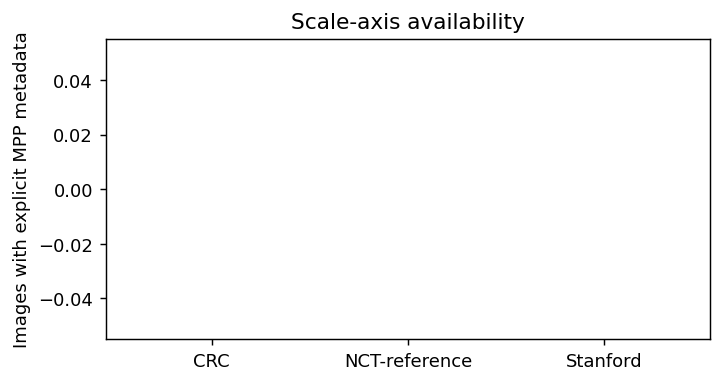

In [6]:
fig,ax=plt.subplots(figsize=(6,3));ax.bar(scale_availability.cohort,scale_availability.explicit_mpp_records);ax.set(ylabel='Images with explicit MPP metadata',title='Scale-axis availability');show_figure(fig)


## 6. Decision and reason

In [7]:
display(Markdown('**Do not test a continuous natural magnification axis.** Documented CRC/NCT scale is constant and Stanford lacks a validated varying per-tile scale field. The measurement required to define levels is unavailable; this is not a negative result about CONCH performance.'))


**Do not test a continuous natural magnification axis.** Documented CRC/NCT scale is constant and Stanford lacks a validated varying per-tile scale field. The measurement required to define levels is unavailable; this is not a negative result about CONCH performance.

In [8]:
manifest=[dict(path=p.name,bytes=p.stat().st_size,sha256=sha256(p)) for p in sorted(OUT.iterdir()) if p.is_file() and p.name!='OUTPUT_MANIFEST.json'];(OUT/'OUTPUT_MANIFEST.json').write_text(json.dumps(manifest,indent=2));print('Outputs:',OUT.resolve())


Outputs: /ewsc/yektefai/spectra_runs/all_axes_inline_20261109/conch/conch-gpt-r2/conch-gpt-r2-test-06-outputs
